In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Binomia Negativa por soma de Bernoullis

In [21]:
r = 10
p = 0.3
n = 10000
bin_neg1 = []
for i in range(n):
    sucess = 0
    tent = 0
    while sucess < r: 
        if np.random.uniform(0,1) > p:
            tent+=1
        else:
            tent+=1
            sucess+=1
    bin_neg1.append(tent)
#print(bin_neg1)

(array([ 202., 1309., 2569., 2987., 1647.,  774.,  374.,   95.,   38.,
           5.]),
 array([ 2. ,  8.3, 14.6, 20.9, 27.2, 33.5, 39.8, 46.1, 52.4, 58.7, 65. ]),
 <BarContainer object of 10 artists>)

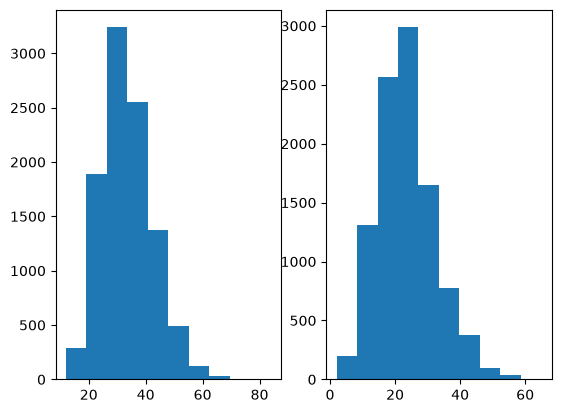

In [22]:
fig, ax = plt.subplots(1,2)
ax[0].hist(bin_neg1)
ax[1].hist(np.random.negative_binomial(r,p,size = n))

Binomial negativa por soma de geométricas.

(array([ 25., 137., 268., 286., 169.,  71.,  33.,   9.,   1.,   1.]),
 array([12. , 18.3, 24.6, 30.9, 37.2, 43.5, 49.8, 56.1, 62.4, 68.7, 75. ]),
 <BarContainer object of 10 artists>)

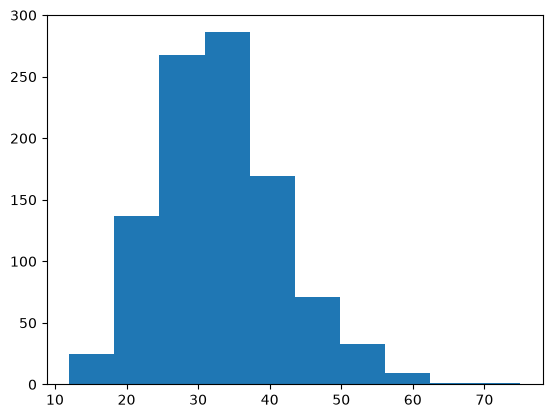

In [33]:
p = 0.3
r = 10 
K = 1000
U = np.random.uniform(0, 1, size=(K, r))
matriz_geometricas = np.ceil(np.log(U) / np.log(1 - p))
bin_neg2 = np.sum(matriz_geometricas, axis=1)
plt.hist(bin_neg2)

Binomial negativa via recursão.

(array([3.210e+02, 1.887e+03, 3.235e+03, 2.567e+03, 1.272e+03, 5.370e+02,
        1.380e+02, 3.100e+01, 1.000e+01, 2.000e+00]),
 array([12. , 19.2, 26.4, 33.6, 40.8, 48. , 55.2, 62.4, 69.6, 76.8, 84. ]),
 <BarContainer object of 10 artists>)

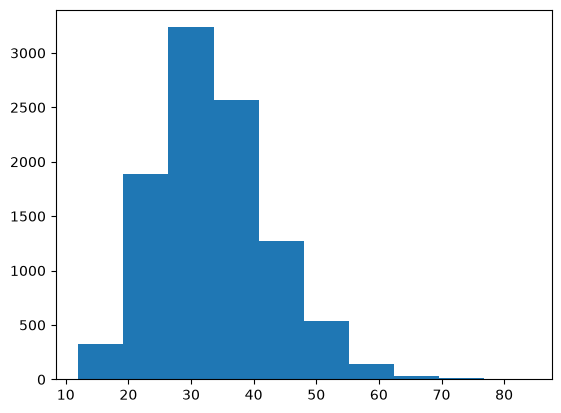

In [34]:
bin_recursao = []
r = 10       
p = 0.3 
for i in range(10000):
    
    U = np.random.uniform(0, 1)
    n = r
    pi = p**r 
    F = pi
    
    while U > F:
        pi = pi*(n/(n-r+1))*(1-p)
        n += 1
        F += pi
        
    bin_recursao.append(n)
    
plt.hist(bin_recursao)

Hipergeométrica por embaralhamento

In [38]:
K = 10000

M = 2
N = 15
n = 3
def hipergeometrica(M,N,n,K):
    hipers =[]
    for _ in range(K):
        lista = [1] * M + [0] * (N)
        for i in range(n):
            u = np.random.uniform()
            pos = int(np.floor(((N+M)-i)*u + i))
            lista[i],lista[pos] = lista[pos], lista[i]
        hipers.append(np.sum(lista[:n]))
    return hipers
hipers = hipergeometrica(M,N,n,K)

(array([6679.,    0.,    0., 3094.,    0.,    0.,  227.]),
 array([0.        , 0.28571429, 0.57142857, 0.85714286, 1.14285714,
        1.42857143, 1.71428571, 2.        ]),
 <BarContainer object of 7 artists>)

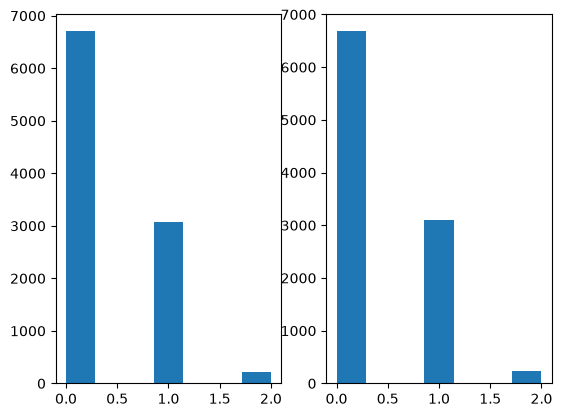

In [41]:
fig, ax = plt.subplots(1,2)
ax[0].hist(hipers, bins=7)
ax[1].hist(np.random.hypergeometric(M, N, n, size=K), bins=7)

Como é possível observar, fazendo com a binomial p =M/M+N , se aproximou muito da nossa hipergeométrica.

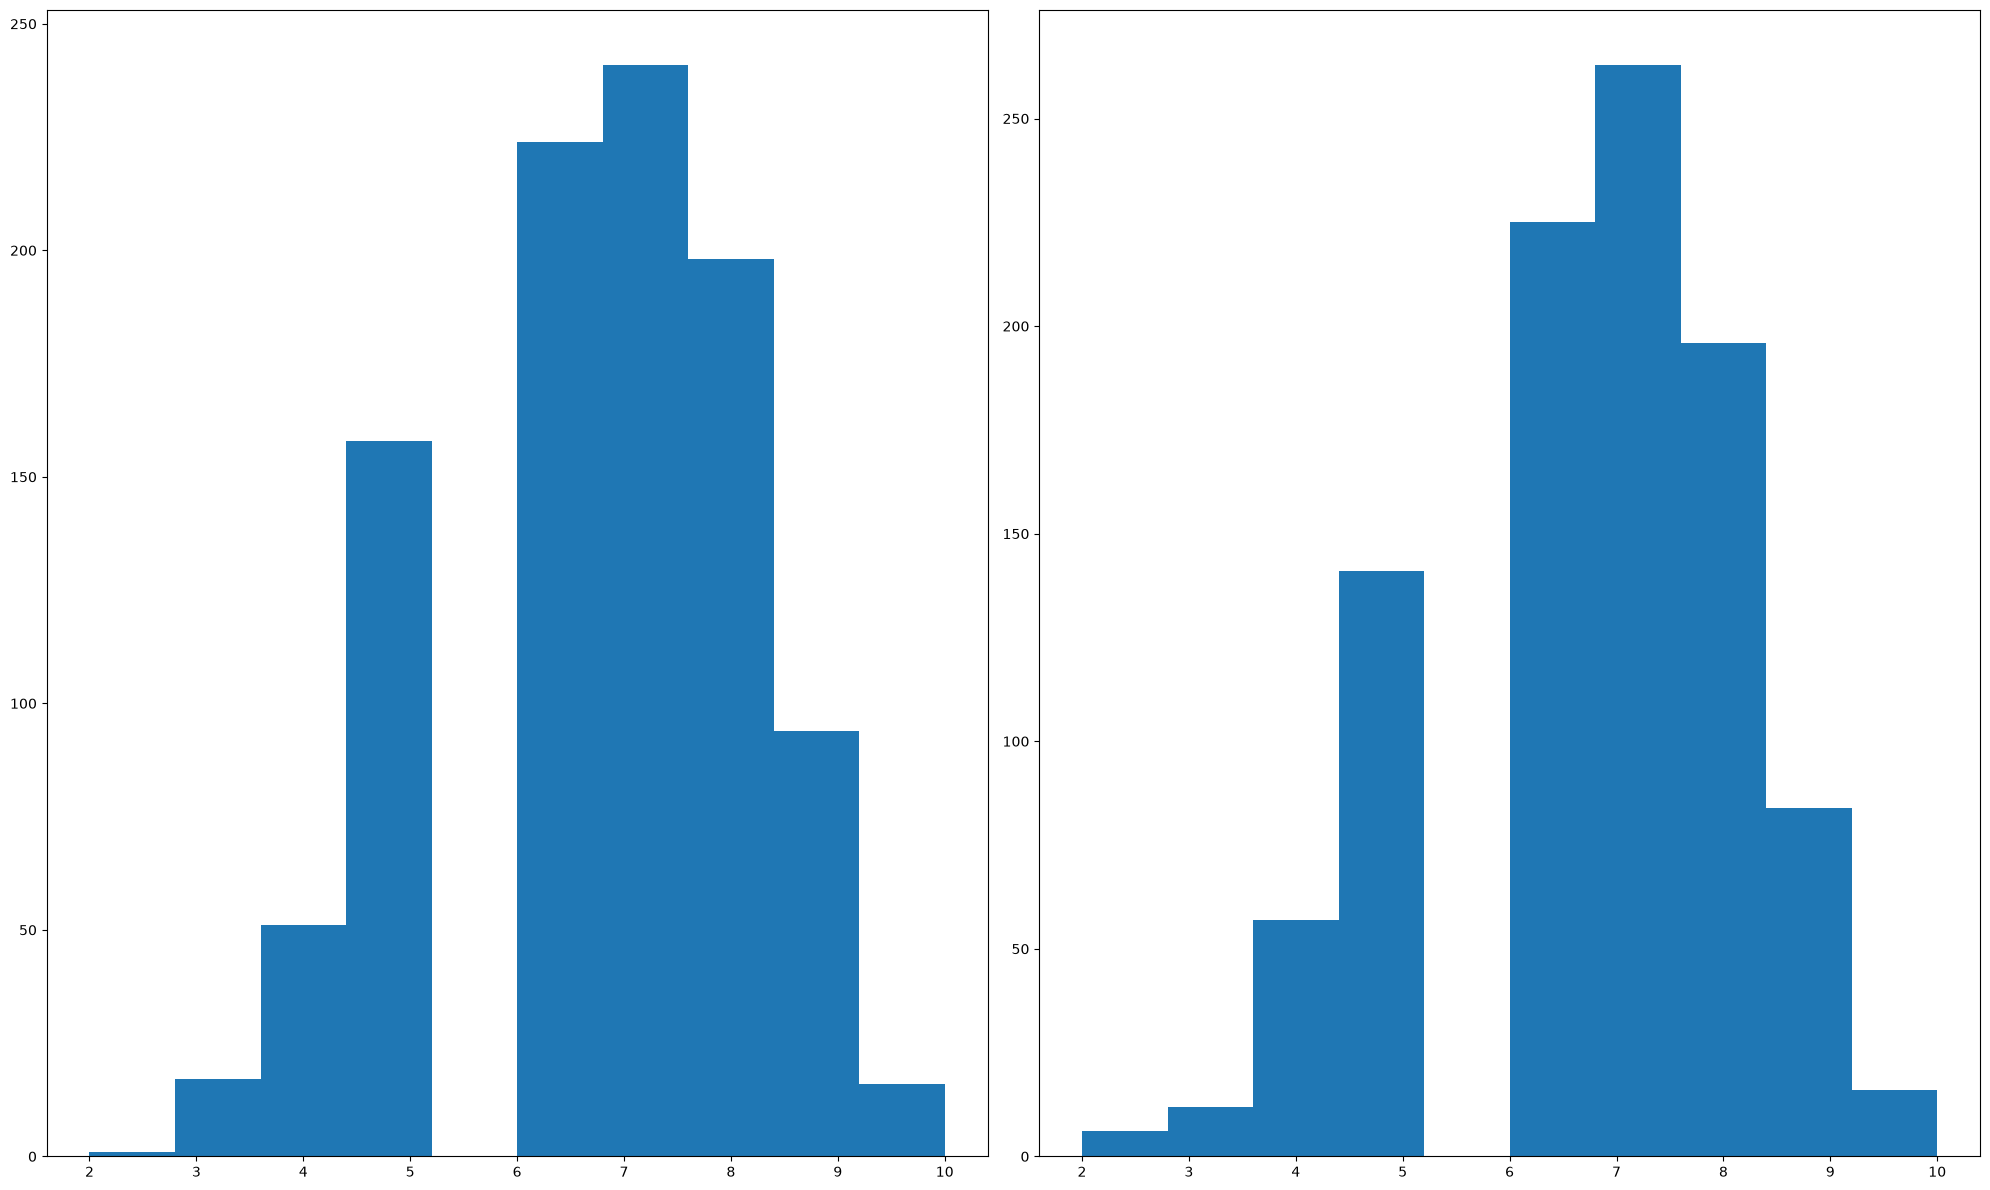

In [52]:
fig, ax = plt.subplots(1,2, figsize=(20,12))
N = 50_000
M = 100_000
n = 10
K = 1000
hiper = hipergeometrica(M,N,n,K)
ax[0].hist((hiper))
ax[1].hist(np.random.binomial(n, M/(M+N), size = K))
plt.tight_layout()